# Lab: Does the Encoding Choice Matter?
**Dataset:** Adult Income (UCI) | **Task:** Binary classification (income >50K)

**Name:** Said Hussain Saim  **ID:** 232-35-429  **Date:** 16 November 2026

Sections 1-2 (imports and data loading) are provided. **Your work starts at Section 3.**
Use `SEED = 42` everywhere so results are reproducible.

## 1. Imports and settings

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

SEED = 42
np.random.seed(SEED)

## 2. Load the data

In [2]:
adult = fetch_openml("adult", version=2, as_frame=True)
df = adult.frame.copy()
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


---
# YOUR WORK STARTS HERE

## 3. Clean the data
Complete all of the following (add as many cells as you need):
- Rename the target column (`class`) to `income`.
- Inspect the data: shape, data types, duplicates, and class balance of the target.
- Find the missing values. They may appear as `NaN` **or** as the string `?` (check both), mainly in `workclass`, `occupation`, and `native-country`. Replace them with the category `"Unknown"`.
- `education-num` is a numeric copy of `education`. Decide whether to keep it, and explain your decision in a markdown cell (think about whether it is fair for comparing encodings).
- Convert the target to 0/1.

In [3]:
df = df.rename(columns={'class': 'income'})
print('Original shape:', df.shape)
display(df.dtypes.to_frame('dtype'))
print('Duplicate rows:', df.duplicated().sum())
display(df['income'].value_counts(normalize=True).rename('proportion'))
cat_initial = df.select_dtypes(include=['category', 'object', 'string']).columns.drop('income')
missing_report = pd.DataFrame({'NaN': df[cat_initial].isna().sum(),
    '?': df[cat_initial].astype('object').eq('?').sum()})
display(missing_report)
for col in cat_initial:
    df[col] = df[col].astype('object').replace('?', np.nan).fillna('Unknown')
df = df.drop(columns='education-num')
# Remove exact duplicates before splitting to avoid identical records crossing sets.
df = df.drop_duplicates().reset_index(drop=True)
labels = df['income'].astype(str).str.strip().str.rstrip('.')
assert set(labels.unique()) == {'<=50K', '>50K'}
df['income'] = labels.map({'<=50K': 0, '>50K': 1}).astype(int)
print('Clean shape:', df.shape)
assert not df.isna().any().any()

Original shape: (48842, 15)


,dtype
age,int64
workclass,category
fnlwgt,int64
education,category
education-num,int64
marital-status,category
occupation,category
relationship,category
race,category
sex,category


Duplicate rows: 52


income
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64

,NaN,?
workclass,2799,0
education,0,0
marital-status,0,0
occupation,2809,0
relationship,0,0
race,0,0
sex,0,0
native-country,857,0


Clean shape: (48790, 14)


I drop `education-num` because it duplicates the information in `education` and would give every encoding an already ordered numeric representation. Exact duplicate rows are removed before splitting to prevent identical examples appearing in both training and test sets.

## 4. Train/test split
- Separate features `X` and target `y`.
- Make one **stratified** split (80/20, `random_state=SEED`).
- Create the lists `num_cols` and `cat_cols` from the training features.
- Print the shapes and the target proportion in both sets to confirm the stratification worked.

In [4]:
X, y = df.drop(columns='income'), df['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Positive proportion:', y_train.mean(), y_test.mean())

Train: (39032, 13) Test: (9758, 13)
Positive proportion: 0.23941893830703012 0.23939331830293092


## 5. Classify the categorical columns
The completed classification table and training-set level counts appear in the output below. Cardinality thresholds are low ≤5, medium 6–20, and high >20.

In [5]:
levels = X_train[cat_cols].nunique()
justifications = {'workclass': 'Employment types have no inherent order.', 'education': 'School attainment has a meaningful progression.', 'marital-status': 'Marital categories have no inherent ranking.', 'occupation': 'Job types have no inherent ranking.', 'relationship': 'Household roles have no inherent ranking.', 'race': 'Race categories have no inherent ranking.', 'sex': 'Sex categories have no inherent ranking.', 'native-country': 'Countries have no inherent ranking.'}
classification = pd.DataFrame({'Column': cat_cols, 'Type': ['Ordinal' if c == 'education' else 'Nominal' for c in cat_cols], '# Levels': levels.values, 'Cardinality': ['Low' if k <= 5 else 'Medium' if k <= 20 else 'High' for k in levels.values], 'Justification': [justifications[c] for c in cat_cols]})
display(classification)
print('Cardinality convention: low ≤5, medium 6–20, high >20; levels counted on training data.')

,Column,Type,# Levels,Cardinality,Justification
0,workclass,Nominal,9,Medium,Employment types have no inherent order.
1,education,Ordinal,16,Medium,School attainment has a meaningful progression.
2,marital-status,Nominal,7,Medium,Marital categories have no inherent ranking.
3,occupation,Nominal,15,Medium,Job types have no inherent ranking.
4,relationship,Nominal,6,Medium,Household roles have no inherent ranking.
5,race,Nominal,5,Low,Race categories have no inherent ranking.
6,sex,Nominal,2,Low,Sex categories have no inherent ranking.
7,native-country,Nominal,42,High,Countries have no inherent ranking.


Cardinality convention: low ≤5, medium 6–20, high >20; levels counted on training data.


## 6. Build the encoders
Create five encoding strategies. Each should be a `ColumnTransformer` (numeric columns are scaled; categorical columns use the encoder).

1. Label encoding (all categorical columns)
2. Ordinal encoding (explicit order for `education`, your choice for the rest)
3. One-hot encoding
4. Frequency encoding
5. Target encoding (**fit on training data only, inside the CV folds**)

Hints:
- `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)` handles unseen categories.
- Frequency and target encoding are not in the basic scikit-learn preprocessing set we covered. Write a small custom transformer class (with `fit` and `transform`) or use `category_encoders` (`pip install category_encoders`).
- Put every encoder **inside a Pipeline** so it is refit on each training fold. Fitting before the split is leakage.

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import TargetEncoder

class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        frame = pd.DataFrame(X)
        self.maps_ = [frame.iloc[:, j].value_counts(normalize=True).to_dict() for j in range(frame.shape[1])]
        return self
    def transform(self, X):
        frame = pd.DataFrame(X)
        return np.column_stack([frame.iloc[:, j].map(m).fillna(0).to_numpy(dtype=float) for j, m in enumerate(self.maps_)])

education_order = ['Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th', '11th', '12th', 'HS-grad', 'Some-college', 'Assoc-voc', 'Assoc-acdm', 'Bachelors', 'Masters', 'Prof-school', 'Doctorate']
# Label encoding of features means arbitrary integer codes, not LabelEncoder on X.
orders = [education_order if c == 'education' else sorted(X_train[c].unique()) for c in cat_cols]
def transformer(categorical):
    return ColumnTransformer([('numeric', StandardScaler(), num_cols), ('categorical', categorical, cat_cols)])
encoders = {
    'label': transformer(OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    'ordinal': transformer(OrdinalEncoder(categories=orders, handle_unknown='use_encoded_value', unknown_value=-1)),
    'onehot': transformer(OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    'frequency': transformer(FrequencyEncoder()),
    # fit_transform uses internal cross-fitting; transform uses training-only mappings.
    'target': transformer(TargetEncoder(target_type='binary', smooth='auto', cv=5, shuffle=True, random_state=SEED)),
}

## 7. Models
Use default settings, identical across all encodings.

In [7]:
models = {
    "LogReg": LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN":    KNeighborsClassifier(),
    "Tree":   DecisionTreeClassifier(random_state=SEED),
}

## 8. Run the experiment
For every (encoding, model) pair:
- 5-fold stratified CV on the **training set** (mean and std of F1)
- Fit once on the full training set and evaluate on the **test set** (accuracy, F1, ROC-AUC)
- Record the number of features after encoding and the training time

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []
def run_one(enc_name, enc, model_name, model):
    pipe = Pipeline([('enc', clone(enc)), ('clf', clone(model))])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1', n_jobs=1, error_score='raise')['test_score']
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    return {'Encoding': enc_name, 'Model': model_name, 'CV F1 mean': scores.mean(), 'CV F1 std': scores.std(), 'Test accuracy': accuracy_score(y_test, pred), 'Test F1': f1_score(y_test, pred), 'Test AUC': roc_auc_score(y_test, prob), '#Features': pipe.named_steps['enc'].transform(X_test.iloc[:1]).shape[1], 'Train time': elapsed}
for enc_name, enc in encoders.items():
    for model_name, model in models.items():
        print('Running:', enc_name, model_name, flush=True)
        results.append(run_one(enc_name, enc, model_name, model))
results_df = pd.DataFrame(results)
results_df

Running: label LogReg
Running: label KNN
Running: label Tree
Running: ordinal LogReg
Running: ordinal KNN
Running: ordinal Tree
Running: onehot LogReg
Running: onehot KNN
Running: onehot Tree
Running: frequency LogReg
Running: frequency KNN
Running: frequency Tree
Running: target LogReg
Running: target KNN
Running: target Tree


,Encoding,Model,CV F1 mean,CV F1 std,Test accuracy,Test F1,Test AUC,#Features,Train time
0,label,LogReg,0.436266,0.003824,0.802521,0.428360,0.815407,13,0.325758
1,label,KNN,0.603980,0.003263,0.827834,0.618875,0.845877,13,0.030973
2,label,Tree,0.614329,0.002428,0.810514,0.610655,0.745459,13,0.130525
3,ordinal,LogReg,0.556867,0.005101,0.823632,0.555182,0.850353,13,0.254885
4,ordinal,KNN,0.610331,0.002223,0.830088,0.624547,0.849784,13,0.029826
5,ordinal,Tree,0.615161,0.009081,0.810207,0.611577,0.746617,13,0.130751
6,onehot,LogReg,0.663675,0.003491,0.849047,0.652184,0.903123,107,0.387486
7,onehot,KNN,0.630806,0.004515,0.831318,0.630942,0.856715,107,0.036326
8,onehot,Tree,0.618279,0.004857,0.814819,0.621729,0.753423,107,0.268867
9,frequency,LogReg,0.516709,0.006723,0.813999,0.515095,0.856005,13,0.091927


## 9. Results table and plots
Produce the final table (columns: Encoding, Model, CV F1 mean ± std, Test F1, Test AUC, #Features, Train time) and at least one plot comparing encodings across models (e.g. a grouped bar chart of Test F1).

In [9]:
# Select winners using training CV, reserving test metrics for final reporting.
winners = results_df.loc[results_df.groupby('Model')['CV F1 mean'].idxmax()]
from IPython.display import Markdown, display
lines = [f"**{r['Model']}**: {r['Encoding']} (CV F1 {r['CV F1 mean']:.4f}; test F1 {r['Test F1']:.4f})." for _, r in winners.iterrows()]
display(Markdown('Best encoding per model by training CV: ' + ' '.join(lines)))

Best encoding per model by training CV: **KNN**: onehot (CV F1 0.6308; test F1 0.6309). **LogReg**: onehot (CV F1 0.6637; test F1 0.6522). **Tree**: target (CV F1 0.6204; test F1 0.6032).

,Encoding,Model,CV F1 mean ± std,Test accuracy,Test F1,Test AUC,#Features,Train time
0,label,LogReg,0.4363 ± 0.0038,0.8025,0.4284,0.8154,13,0.3258
1,label,KNN,0.6040 ± 0.0033,0.8278,0.6189,0.8459,13,0.0310
2,label,Tree,0.6143 ± 0.0024,0.8105,0.6107,0.7455,13,0.1305
3,ordinal,LogReg,0.5569 ± 0.0051,0.8236,0.5552,0.8504,13,0.2549
4,ordinal,KNN,0.6103 ± 0.0022,0.8301,0.6245,0.8498,13,0.0298
5,ordinal,Tree,0.6152 ± 0.0091,0.8102,0.6116,0.7466,13,0.1308
6,onehot,LogReg,0.6637 ± 0.0035,0.8490,0.6522,0.9031,107,0.3875
7,onehot,KNN,0.6308 ± 0.0045,0.8313,0.6309,0.8567,107,0.0363
8,onehot,Tree,0.6183 ± 0.0049,0.8148,0.6217,0.7534,107,0.2689
9,frequency,LogReg,0.5167 ± 0.0067,0.8140,0.5151,0.8560,13,0.0919


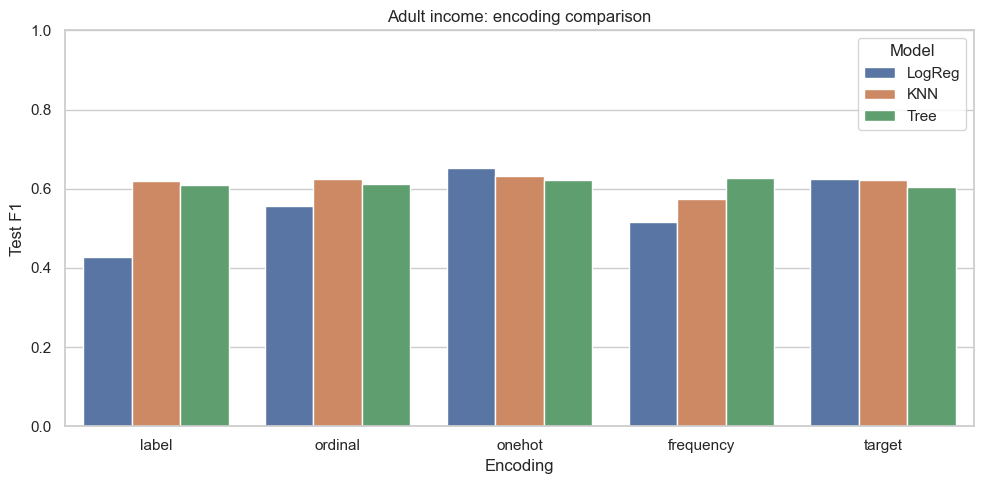

In [10]:
final_table = results_df.copy()
final_table['CV F1 mean ± std'] = final_table.apply(lambda r: f"{r['CV F1 mean']:.4f} ± {r['CV F1 std']:.4f}", axis=1)
display(final_table[['Encoding', 'Model', 'CV F1 mean ± std', 'Test accuracy', 'Test F1', 'Test AUC', '#Features', 'Train time']].round(4))
results_df.to_csv('encoding_lab_results.csv', index=False)
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=results_df, x='Encoding', y='Test F1', hue='Model', ax=ax)
ax.set_title('Adult income: encoding comparison')
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()

## 10. Analysis

**1. Which encoding was best for each model, and why?**

One-hot was best by CV F1 for Logistic Regression (0.6637) and KNN (0.6308).  
Target encoding was best for the Decision Tree by CV (0.6204), while frequency won on test F1 (0.6278).  
Results differ because linear models, distance-based models, and trees use encoded values differently.

**2. Why does label encoding hurt Logistic Regression and KNN more?**

Label encoding gives nominal categories an artificial numerical order.  
This creates misleading linear effects for Logistic Regression and distances for KNN.  
Trees depend on threshold splits, so code spacing matters less, though arbitrary order can still hurt.

**3. How did one-hot encoding affect dimensionality?**

One-hot encoding increased the total features from 13 to 107.  
The `native-country` column alone became 42 indicators, including `Unknown`.  
This avoids artificial ordering but requires more memory and computation.


**Name:** Said Hussain Saim  
**ID:** 232-35-429  
**Date:** 16 November 2026